# EDA 3 — Articles and time: catalogue, popularity, categories, freshness, time of day and recency

Training split of **MIND-small**, except section 5 (cold-start articles in validation and test). Inputs are the processed files from
`1_Data_Preparation/1. data_preparation.ipynb`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Project root = the folder that contains 1_Data_Preparation/processed (written by 1. data_preparation.ipynb)
CODE_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "run_all.py").is_file()
)
ROOT = (
    Path(os.environ.get("NEWSREC_ROOT", CODE_ROOT / "runs/mindsmall-epoch"))
    .expanduser()
    .resolve()
)
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
FIG_DIR = ROOT / "2_EDA" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/anhminhhoang/Documents/GitHub/BT4222-Group-6-


In [2]:
# 1. Load the processed training tables and the article catalogue (text columns are not needed here)
imp_cols = [
    "impression_uid",
    "user_code",
    "timestamp",
    "history_len",
    "slate_len",
    "n_clicks",
]
cand_cols = ["impression_uid", "user_code", "timestamp", "news_code", "clicked"]
text_cols = ["title", "abstract", "url", "title_entities", "abstract_entities"]
imp = pd.read_parquet(PROCESSED / "impressions_train.parquet", columns=imp_cols)
cand = pd.read_parquet(PROCESSED / "candidates_train.parquet", columns=cand_cols)
news = pd.read_parquet(PROCESSED / "news_catalogue.parquet").drop(columns=text_cols)
tr = news[news.in_news_train].copy()  # the training news file, one row per article

# 2. Headline counts
n_imp = len(imp)
n_exp = len(cand)
n_clicks = int(cand["clicked"].sum())
ctr_all = 100 * n_clicks / n_exp
T0 = imp["timestamp"].min()
print(
    "Impressions:",
    n_imp,
    "| Exposures:",
    n_exp,
    "| Clicks:",
    n_clicks,
    f"| CTR {ctr_all:.2f}%",
)
print(
    "Articles in the training news file:",
    len(tr),
    "| shown in a slate:",
    int((tr.exposures_train > 0).sum()),
)

Impressions: 95071 | Exposures: 3389342 | Clicks: 141558 | CTR 4.18%
Articles in the training news file: 43370 | shown in a slate: 13536


# 1. The article catalogue

* Sports is 28% of the catalogue but 11% of exposures; news alone carries 29% of exposures. Exposure shares are MSN's editorial choice,
  not demand.
* Titles are short (median **10 words**, 99% within 20). Abstracts have a median of 27 words, are missing for **5%** and are bimodal.
  About 12% of articles have no linked entity at all. More than a third of the subcategories have fewer than ten articles.

**Model Implications**
* Title-first text encoder (20 tokens for titles, 100 for abstracts covers 99%); mask or title fallback for missing abstracts; a text-only path
  next to entity features; embed or merge subcategories rather than one-hot encode them.

In [3]:
# 1. Catalogue, exposures and clicks by category
by_cat = tr.groupby("category").agg(
    articles=("news_code", "size"),
    shown=("exposures_train", lambda s: int((s > 0).sum())),
    exposures=("exposures_train", "sum"),
    clicks=("clicks_train", "sum"),
)
for col in ["articles", "exposures", "clicks"]:
    by_cat[col + "_pct"] = 100 * by_cat[col] / by_cat[col].sum()
by_cat["ctr"] = 100 * by_cat.clicks / by_cat.exposures
by_cat = by_cat.sort_values("articles", ascending=False)
print(by_cat.round(2))

# 2. Text and entity availability
sub = tr.subcategory.value_counts()
abstracts = tr.loc[tr.has_abstract, "abstract_len_words"]
no_entity = (tr.n_title_entities + tr.n_abstract_entities) == 0
print(
    f"\nCategories: {tr.category.nunique()} ({(by_cat.exposures > 0).sum()} ever shown)"
)
print(f"Subcategories: {len(sub)} ({(sub < 10).sum()} with < 10 articles)")
print(
    f"Title words: median {tr.title_len_words.median():.0f}, p99 {tr.title_len_words.quantile(0.99):.0f}"
)
print(
    f"Abstract words (when present): median {abstracts.median():.0f}, p99 {abstracts.quantile(0.99):.0f}"
)
print(f"Abstract missing: {100 * (1 - tr.has_abstract.mean()):.1f}%")
print(f"Articles with no title entity: {100 * (tr.n_title_entities == 0).mean():.1f}%")
print(f"Articles with no entity at all: {100 * no_entity.mean():.1f}%")

               articles  shown  exposures  clicks  articles_pct  exposures_pct  clicks_pct   ctr
category                                                                                        
news              13260   3645     991670   43886         30.57          29.26       31.00  4.43
sports            12320   3968     375142   19758         28.41          11.07       13.96  5.27
finance            2585    791     324574   13329          5.96           9.58        9.42  4.11
foodanddrink       2166    665     195674    5620          4.99           5.77        3.97  2.87
lifestyle          2092    776     322668   11883          4.82           9.52        8.39  3.68
travel             1946    753     164081    4599          4.49           4.84        3.25  2.80
weather            1694    650      48271    1808          3.91           1.42        1.28  3.75
video              1680    602      45159    1810          3.87           1.33        1.28  4.01
health             1673    506

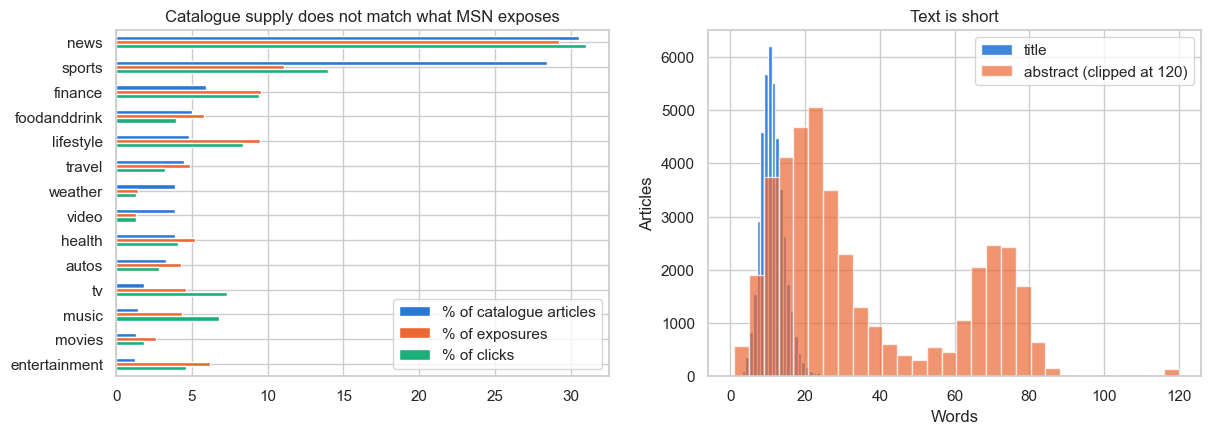

In [4]:
# Plot
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
by_cat.head(14)[["articles_pct", "exposures_pct", "clicks_pct"]].plot(
    kind="barh", ax=ax[0]
)
ax[0].invert_yaxis()
ax[0].legend(["% of catalogue articles", "% of exposures", "% of clicks"])
ax[0].set(title="Catalogue supply does not match what MSN exposes", ylabel="")
ax[1].hist(tr.title_len_words, bins=range(31), alpha=0.9, label="title")
ax[1].hist(
    abstracts.clip(upper=120), bins=30, alpha=0.7, label="abstract (clipped at 120)"
)
ax[1].set(xlabel="Words", ylabel="Articles", title="Text is short")
ax[1].legend()
plt.savefig(FIG_DIR / "art_01_catalogue.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Article popularity

One row per article shown in the window: exposures, clicks and CTR over the whole training window (retrospective totals).
* **4% of shown articles collect 80% of clicks** (Gini 0.95); the median shown article has 7 exposures and no click; 63% of shown articles are
  never clicked in the window.
* Article CTR scatters wildly below a hundred exposures and converges towards the overall 4% as exposure grows.

**Model Implications**
* Popularity is a strong signal but must be **time-causal** (prior exposures, prior clicks, a smoothed prior CTR computed from events before
  the impression). Raw whole-window CTR is neither reliable nor leak-free.

In [5]:
# 1. One row per shown article
art = tr[tr.exposures_train > 0][
    ["news_code", "category", "exposures_train", "clicks_train"]
]
art = art.rename(columns={"exposures_train": "exposures", "clicks_train": "clicks"})
art["ctr"] = 100 * art.clicks / art.exposures
print(art[["exposures", "clicks", "ctr"]].describe().round(2))

# 2. Concentration: articles needed for 80% of clicks, Gini coefficient
ranked = art.sort_values("clicks", ascending=False).reset_index(drop=True)
cum = 100 * ranked.clicks.cumsum() / ranked.clicks.sum()
n80 = int((cum < 80).sum()) + 1
cl = np.sort(art.clicks.values)
n = len(cl)
gini = 2 * np.sum(np.arange(1, n + 1) * cl) / (n * cl.sum()) - (n + 1) / n
print(
    f"\n{n80:,} articles ({100 * n80 / n:.1f}% of {n:,} shown) account for 80% of clicks"
)
print(f"Gini coefficient of clicks: {gini:.2f}")
print(f"Shown articles never clicked: {100 * (art.clicks == 0).mean():.1f}%")

# 3. Exposure buckets
bucket_labels = ["<10", "10-99", "100-999", "1k-10k", "10k+"]
art["bucket"] = pd.cut(art.exposures, [0, 9, 99, 999, 9999, 1e9], labels=bucket_labels)
pop = art.groupby("bucket", observed=True).agg(
    articles=("news_code", "size"),
    exposures=("exposures", "sum"),
    clicks=("clicks", "sum"),
    never_clicked=("clicks", lambda s: 100 * (s == 0).mean()),
)
pop["exposure_pct"] = 100 * pop.exposures / pop.exposures.sum()
pop["ctr"] = 100 * pop.clicks / pop.exposures
print("\nBy exposure bucket:")
print(pop.round(2))

       exposures    clicks       ctr
count   13536.00  13536.00  13536.00
mean      250.39     10.46      4.22
std      1016.10     87.42     11.72
min         1.00      0.00      0.00
25%         2.00      0.00      0.00
50%         7.00      0.00      0.00
75%        29.00      1.00      3.15
max     18314.00   4316.00    100.00

538 articles (4.0% of 13,536 shown) account for 80% of clicks
Gini coefficient of clicks: 0.95
Shown articles never clicked: 62.7%

By exposure bucket:
         articles  exposures  clicks  never_clicked  exposure_pct   ctr
bucket                                                                 
<10          7711      26394    1203          86.49          0.78  4.56
10-99        3588     101799    3913          49.08          3.00  3.84
100-999      1381     549561   16217           4.34         16.21  2.95
1k-10k        827    2343069   91411           0.00         69.13  3.90
10k+           29     368519   28814           0.00         10.87  7.82


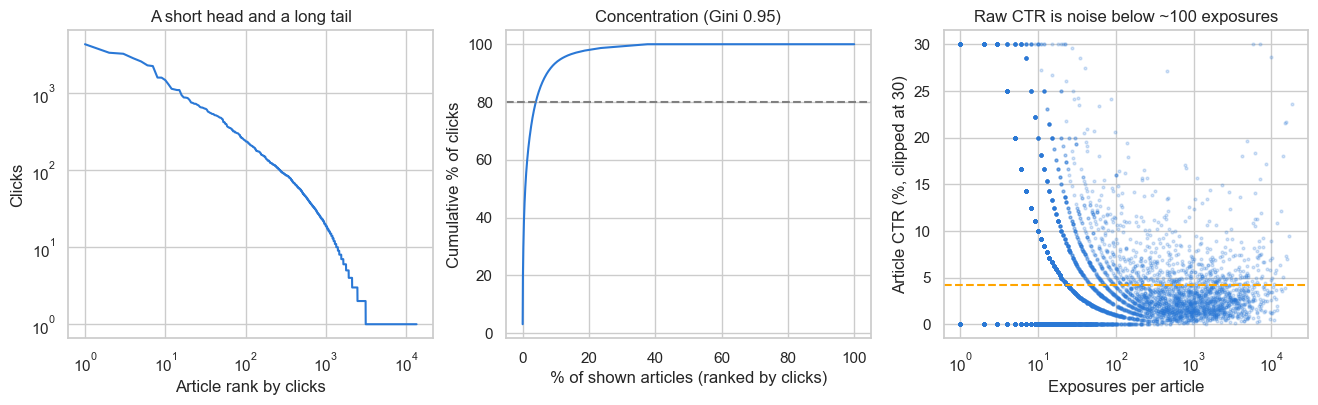

In [6]:
# Plot
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(range(1, n + 1), ranked.clicks.clip(lower=1))
ax[0].set(xscale="log", yscale="log", xlabel="Article rank by clicks", ylabel="Clicks")
ax[0].set_title("A short head and a long tail")
ax[1].plot(100 * np.arange(1, n + 1) / n, cum)
ax[1].axhline(80, color="grey", ls="--")
ax[1].set(
    xlabel="% of shown articles (ranked by clicks)", ylabel="Cumulative % of clicks"
)
ax[1].set_title(f"Concentration (Gini {gini:.2f})")
ax[2].scatter(art.exposures, art.ctr.clip(upper=30), s=4, alpha=0.2)
ax[2].axhline(ctr_all, color="orange", ls="--")
ax[2].set(
    xscale="log",
    xlabel="Exposures per article",
    ylabel="Article CTR (%, clipped at 30)",
)
ax[2].set_title("Raw CTR is noise below ~100 exposures")
plt.savefig(FIG_DIR / "art_02_popularity.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Category engagement

Category is available for every article, including cold-start ones. The risk is confounding: category CTR may only reflect how much exposure
each category's articles received, so the second view compares categories inside exposure buckets.
* Category CTR spans **2.7% (autos) to 6.6% (tv, music)**. Within exposure buckets sports stays above the bucket average and travel,
  lifestyle, food and drink, health and entertainment stay below; tv and music earn their edge on the 1k-10k exposure band.

**Model Implications**
* Keep `category` as a feature: it survives exposure control, spans a 2.4× range and is one of the few signals for cold-start articles.

In [7]:
# 1. Raw category CTR
cat_ctr = by_cat[by_cat.exposures > 0].sort_values("ctr", ascending=False)
print(cat_ctr[["shown", "exposures", "ctr"]].round(2))

# 2. CTR of each category minus the average of articles with similar exposure
cell = art.groupby(["category", "bucket"], observed=True).agg(
    exposures=("exposures", "sum"), clicks=("clicks", "sum")
)
cell = cell.reset_index()
cell["ctr"] = 100 * cell.clicks / cell.exposures
bucket_tot = cell.groupby("bucket", observed=True)[["clicks", "exposures"]].sum()
bucket_avg = 100 * bucket_tot.clicks / bucket_tot.exposures
cell["dev_pp"] = cell.ctr - cell.bucket.map(bucket_avg).astype(float)

# 3. Heatmap table: major categories (>= 40k exposures), cells with >= 2k exposures
major = cat_ctr[cat_ctr.exposures >= 40_000].index.tolist()
big_cells = cell[cell.category.isin(major) & (cell.exposures >= 2_000)]
heat = (
    big_cells.pivot(index="category", columns="bucket", values="dev_pp")
    .reindex(major)
    .astype(float)
)
print("\nCTR minus the exposure-bucket average (pp):")
print(heat.round(1))

               shown  exposures   ctr
category                             
tv               211     156228  6.63
music            193     146687  6.56
sports          3968     375142  5.27
news            3645     991670  4.43
finance          791     324574  4.11
video            602      45159  4.01
weather          650      48271  3.75
lifestyle        776     322668  3.68
northamerica       1         28  3.57
health           506     175412  3.30
entertainment    179     210573  3.09
movies           170      88347  2.97
foodanddrink     665     195674  2.87
travel           753     164081  2.80
autos            418     144698  2.74
kids               8        130  2.31

CTR minus the exposure-bucket average (pp):
bucket         <10  10-99  100-999  1k-10k  10k+
category                                        
tv             NaN    NaN      0.6     3.6  -3.2
music          NaN    NaN      0.4     3.6  -3.8
sports         1.5    1.4      0.5     0.6   3.3
news          -0.5    0.1 

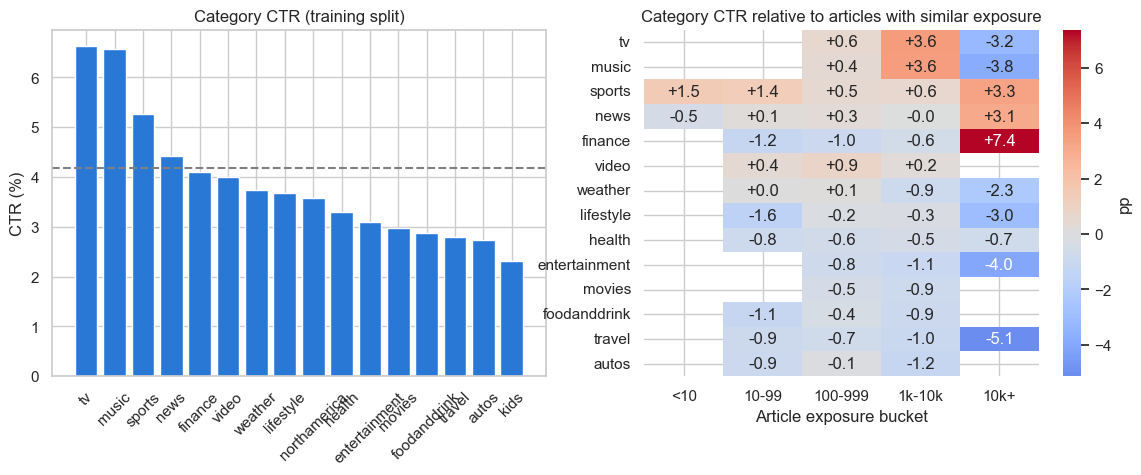

In [8]:
# Plot
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(cat_ctr.index, cat_ctr.ctr)
ax[0].axhline(ctr_all, color="grey", ls="--")
ax[0].tick_params(axis="x", rotation=45)
ax[0].set(ylabel="CTR (%)", title="Category CTR (training split)")
sns.heatmap(
    heat,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt="+.1f",
    ax=ax[1],
    cbar_kws={"label": "pp"},
)
ax[1].set(xlabel="Article exposure bucket", ylabel="")
ax[1].set_title("Category CTR relative to articles with similar exposure")
plt.savefig(FIG_DIR / "art_03_category_ctr.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Freshness and time-causal popularity

Article age is measured from the article's **first recorded exposure** in the training window; articles already present in the first hours of
the log are older than that (left-censored, 27% of exposures). Prior popularity is computed strictly before the impression: the article's clicks
in all completed hours before the current one.
* For articles first seen after the log opened, CTR falls from **5 to 7% in the first hours to about 3% after two days**.
* Observed lifespan (first to last exposure) runs from a median of 1 hour (video) to over 12 hours (finance, autos, food) for all shown
  articles; restricting to articles with at least 10 exposures lengthens every median because single-exposure articles have a zero span.
* Prior clicks separate CTR strongly: articles with **100 or more clicks before the impression** are clicked at 6.4%, 1,000 or more at 16%,
  against about 3% below; articles with no prior click (9% of exposures) are brand new and benefit from freshness.

**Model Implications**
* `article_age_hours` (from first observed exposure, with a censoring flag) and a category-specific decay; hourly time-causal popularity modelled
  jointly with age. New articles need content and category.

In [9]:
# 1. Age of the article at each exposure, measured from its first observed exposure in the window
age_labels = ["<1h", "1-3h", "3-6h", "6-12h", "12-24h", "24-48h", "48-72h", ">72h"]
age = cand.merge(news[["news_code", "first_exposure_train"]], on="news_code")
age["age_h"] = (age.timestamp - age.first_exposure_train).dt.total_seconds() / 3600
age["censored"] = age.first_exposure_train < T0 + pd.Timedelta(hours=6)
age["age_bin"] = pd.cut(
    age.age_h, [-1, 1, 3, 6, 12, 24, 48, 72, 1e9], labels=age_labels
)
age_tbl = age.groupby(["censored", "age_bin"], observed=True).agg(
    exposures=("clicked", "size"), clicks=("clicked", "sum")
)
age_tbl = age_tbl.reset_index()
age_tbl["ctr"] = 100 * age_tbl.clicks / age_tbl.exposures
age_ctr = age_tbl.pivot(index="age_bin", columns="censored", values="ctr")
age_ctr = age_ctr.rename(
    columns={False: "first seen in window", True: "present at start (censored)"}
)
censored_pct = 100 * age_tbl[age_tbl.censored].exposures.sum() / n_exp
print("CTR (%) by hours since the article's first recorded exposure:")
print(age_ctr.round(2))
print(f"Exposures on age-censored articles: {censored_pct:.0f}%")

# 2. Observed lifespan by category (first to last exposure)
life = tr[tr.exposures_train > 0].copy()
life["life_h"] = (
    life.last_exposure_train - life.first_exposure_train
).dt.total_seconds() / 3600
lifespan = life.groupby("category").life_h.agg(
    articles="size",
    median="median",
    p25=lambda s: s.quantile(0.25),
    p75=lambda s: s.quantile(0.75),
)
lifespan["median_10plus_exposures"] = (
    life[life.exposures_train >= 10].groupby("category").life_h.median()
)
lifespan = lifespan[lifespan.articles >= 100].sort_values("median")
print("\nObserved lifespan in hours (first to last exposure), shown articles:")
print(lifespan.round(1))

# 3. Time-causal popularity: clicks the article collected in completed hours before the impression
cand_h = cand[["news_code", "timestamp", "clicked"]].copy()
cand_h["h"] = ((cand_h.timestamp - T0).dt.total_seconds() // 3600).astype(int)
hourly = (
    cand_h.groupby(["news_code", "h"])
    .clicked.sum()
    .reset_index(name="c")
    .sort_values(["news_code", "h"])
)
hourly["prior_clicks"] = hourly.groupby("news_code").c.cumsum() - hourly.c
prior = cand_h.merge(hourly[["news_code", "h", "prior_clicks"]], on=["news_code", "h"])
prior["bin"] = pd.cut(
    prior.prior_clicks,
    [-1, 0, 9, 99, 999, 1e9],
    labels=["0", "1-9", "10-99", "100-999", "1000+"],
)
prior = prior.groupby("bin", observed=True).agg(
    exposures=("clicked", "size"), clicks=("clicked", "sum")
)
prior["ctr"] = 100 * prior.clicks / prior.exposures
prior["exposure_pct"] = 100 * prior.exposures / prior.exposures.sum()
print("\nCTR by the article's clicks in completed hours before the impression:")
print(prior.round(2))

CTR (%) by hours since the article's first recorded exposure:
censored  first seen in window  present at start (censored)
age_bin                                                    
<1h                       5.37                         3.68
1-3h                      6.65                         4.09
3-6h                      5.91                         3.99
6-12h                     4.83                         3.76
12-24h                    4.10                         3.39
24-48h                    4.65                         2.49
48-72h                    3.31                         2.48
>72h                      3.14                         2.50
Exposures on age-censored articles: 27%

Observed lifespan in hours (first to last exposure), shown articles:
               articles  median  p25   p75  median_10plus_exposures
category                                                           
video               602     1.1  0.2   6.1                     10.5
sports             3968 


CTR by the article's clicks in completed hours before the impression:
         exposures  clicks    ctr  exposure_pct
bin                                            
0           289588    9128   3.15          8.54
1-9         777954   21342   2.74         22.95
10-99      1510554   51091   3.38         44.57
100-999     729373   46588   6.39         21.52
1000+        81873   13409  16.38          2.42


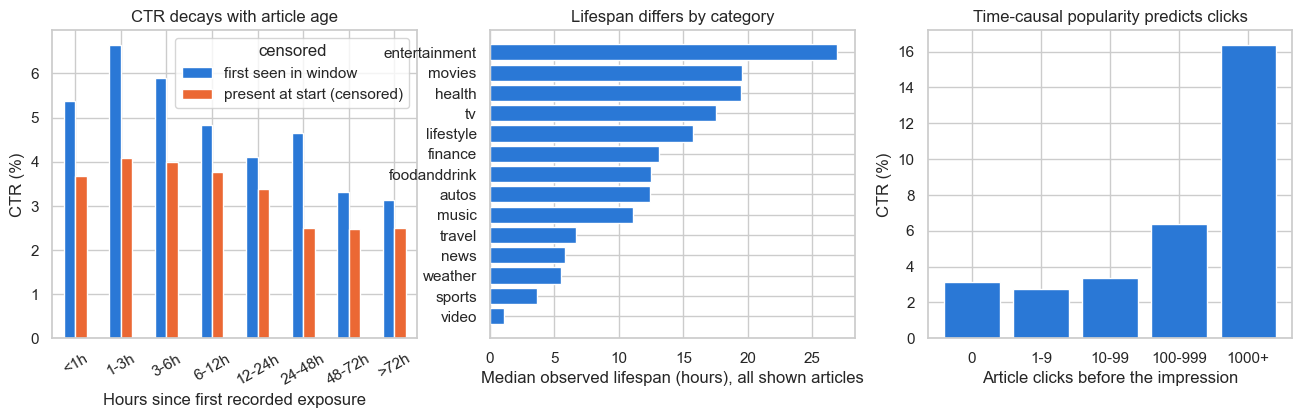

In [10]:
# Plot
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
age_ctr.plot(kind="bar", ax=ax[0], rot=30)
ax[0].set(
    xlabel="Hours since first recorded exposure",
    ylabel="CTR (%)",
    title="CTR decays with article age",
)
ax[1].barh(lifespan.index, lifespan["median"])
ax[1].set(
    xlabel="Median observed lifespan (hours), all shown articles",
    title="Lifespan differs by category",
)
ax[2].bar(prior.index.astype(str), prior.ctr)
ax[2].set(xlabel="Article clicks before the impression", ylabel="CTR (%)")
ax[2].set_title("Time-causal popularity predicts clicks")
plt.savefig(FIG_DIR / "art_04_freshness_popularity.png", dpi=150, bbox_inches="tight")
plt.show()
del age, cand_h, hourly

# 5. Cold-start articles in validation and test

An article is cold for the model when it was never shown in the training window. The split is by day, so later days contain new articles.
* On the validation day 79% of exposures still fall on articles shown in train, but on the test day **77% of exposures and 85% of clicks** are
  on articles never shown in train, almost all absent from the training news file altogether.

**Model Implications**
* Candidate generation cannot rely on item ids or in-window popularity alone: on the test day it would miss most of the clicks. Content
  representations and a popularity that updates through the test day are required.

In [11]:
# 1. Status of every validation / test candidate relative to the training window
order = ["shown in train", "in train histories only", "absent from train"]
rows = []
for split in ["validation", "test"]:
    cs = pd.read_parquet(
        PROCESSED / f"candidates_{split}.parquet", columns=["news_code", "clicked"]
    )
    cs = cs.merge(
        news[["news_code", "exposures_train", "in_news_train"]],
        on="news_code",
        how="left",
    )
    cs["status"] = np.select(
        [cs.exposures_train > 0, cs.in_news_train], order[:2], default=order[2]
    )
    g = (
        cs.groupby("status")
        .agg(
            articles=("news_code", "nunique"),
            exposures=("clicked", "size"),
            clicks=("clicked", "sum"),
        )
        .reset_index()
    )
    g["split"] = split
    g["exposure_pct"] = 100 * g.exposures / g.exposures.sum()
    g["click_pct"] = 100 * g.clicks / g.clicks.sum()
    rows.append(g)
cold = pd.concat(rows)
print(cold.round(1).to_string(index=False))

                 status  articles  exposures  clicks      split  exposure_pct  click_pct
      absent from train      3393     253136   12028 validation          20.6       25.1
in train histories only        49       3037     119 validation           0.2        0.2
         shown in train      2642     975500   35814 validation          79.2       74.7
      absent from train      4513     940837   39978       test          77.0       85.4
in train histories only        65      38380    1063       test           3.1        2.3
         shown in train      1566     243212    5784       test          19.9       12.4


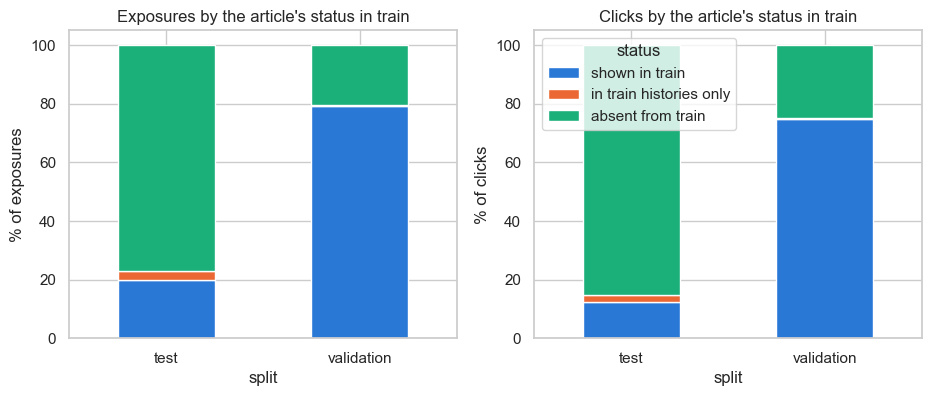

In [12]:
# Plot
exposure_share = cold.pivot(index="split", columns="status", values="exposure_pct")[
    order
]
click_share = cold.pivot(index="split", columns="status", values="click_pct")[order]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
exposure_share.plot(kind="bar", stacked=True, ax=ax[0], rot=0, legend=False)
ax[0].set(ylabel="% of exposures", title="Exposures by the article's status in train")
click_share.plot(kind="bar", stacked=True, ax=ax[1], rot=0)
ax[1].set(ylabel="% of clicks", title="Clicks by the article's status in train")
plt.savefig(FIG_DIR / "art_05_cold_start_articles.png", dpi=150, bbox_inches="tight")
plt.show()

# 6. Time of day

Volume and engagement by hour of the log clock (timezone undocumented). Because CTR tracks slate length, engagement is measured as **clicks per
impression**; to separate a time effect from who is online, each user's series is also centred on the user's own mean.
* Volume follows a strong daily cycle and is more than twice as high on the weekdays (11 and 12 Nov) as on the weekend.
* Engagement moves far less: within-user clicks per impression stay within **±0.07** of the user's mean, and hourly CTR deviations remain
  within half a percentage point. All categories share the same diurnal pattern.

**Model Implications**
* Hour of day is a cheap context feature that mostly improves calibration rather than ranking (it does not separate candidates within a slate).
  Model it as a coarse day-part.

In [13]:
# 1. Volume per day and per hour
daily = imp.groupby(imp.timestamp.dt.date).agg(
    impressions=("n_clicks", "size"), users=("user_code", "nunique")
)
print("Impressions per day:")
print(daily)
hourly_vol = imp.groupby(imp.timestamp.dt.floor("h")).size()

# 2. Engagement by hour of day: raw deviation and within-user deviation of clicks per impression; CTR deviation
imp["hour"] = imp.timestamp.dt.hour
multi = imp[imp.groupby("user_code").impression_uid.transform("size") > 1].copy()
multi["dev"] = multi.n_clicks - multi.groupby("user_code").n_clicks.transform("mean")
by_hour = imp.groupby("hour").agg(
    impressions=("n_clicks", "size"),
    clicks=("n_clicks", "sum"),
    exposures=("slate_len", "sum"),
)
by_hour["impression_pct"] = 100 * by_hour.impressions / n_imp
by_hour["raw_dev"] = by_hour.clicks / by_hour.impressions - n_clicks / n_imp
by_hour["within_user"] = multi.groupby("hour").dev.mean()
by_hour["ctr_dev_pp"] = 100 * by_hour.clicks / by_hour.exposures - ctr_all
print("\nBy hour of day:")
print(by_hour[["impression_pct", "raw_dev", "within_user", "ctr_dev_pp"]].round(3))

# 3. Category x hour: CTR deviation from the category's own CTR
ch = cand.merge(news[["news_code", "category"]], on="news_code")
ch["hour"] = ch.timestamp.dt.hour
ch = (
    ch.groupby(["category", "hour"])
    .agg(exposures=("clicked", "size"), clicks=("clicked", "sum"))
    .reset_index()
)
cat_tot = ch.groupby("category")[["exposures", "clicks"]].sum()
cat_tot["ctr"] = 100 * cat_tot.clicks / cat_tot.exposures
ch["dev_pp"] = 100 * ch.clicks / ch.exposures - ch.category.map(cat_tot.ctr)
majors = cat_tot[cat_tot.exposures >= 40_000].sort_values("ctr", ascending=False).index
big_cells = ch[(ch.exposures >= 500) & ch.category.isin(majors)]
heat = (
    big_cells.pivot(index="category", columns="hour", values="dev_pp")
    .reindex(majors)
    .astype(float)
)

Impressions per day:
            impressions  users
timestamp                     
2019-11-09        13570   9865
2019-11-10        15048  10726
2019-11-11        32799  21298
2019-11-12        33654  22011

By hour of day:
      impression_pct  raw_dev  within_user  ctr_dev_pp
hour                                                  
0              0.719    0.036        0.065      -0.098
1              0.810    0.095        0.044      -0.042
2              1.279    0.050        0.064       0.032
3              2.119    0.066        0.050      -0.120
4              3.553    0.047        0.012      -0.148
5              5.580    0.066        0.037      -0.038
6              6.806    0.025        0.016       0.119
7              7.413    0.006        0.002       0.352
8              7.967   -0.026       -0.011       0.406
9              5.876   -0.040       -0.028       0.409
10             7.473    0.029        0.009       0.144
11             7.719   -0.011       -0.020       0.219
12    

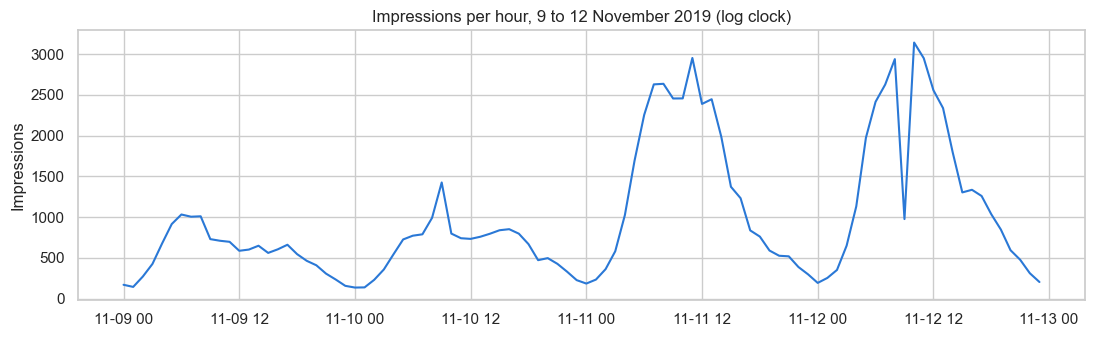

In [14]:
# Plot 1 of 3
plt.figure(figsize=(13, 3.5))
plt.plot(hourly_vol.index, hourly_vol.values)
plt.title("Impressions per hour, 9 to 12 November 2019 (log clock)")
plt.ylabel("Impressions")
plt.savefig(FIG_DIR / "art_06_hourly_volume.png", dpi=150, bbox_inches="tight")
plt.show()

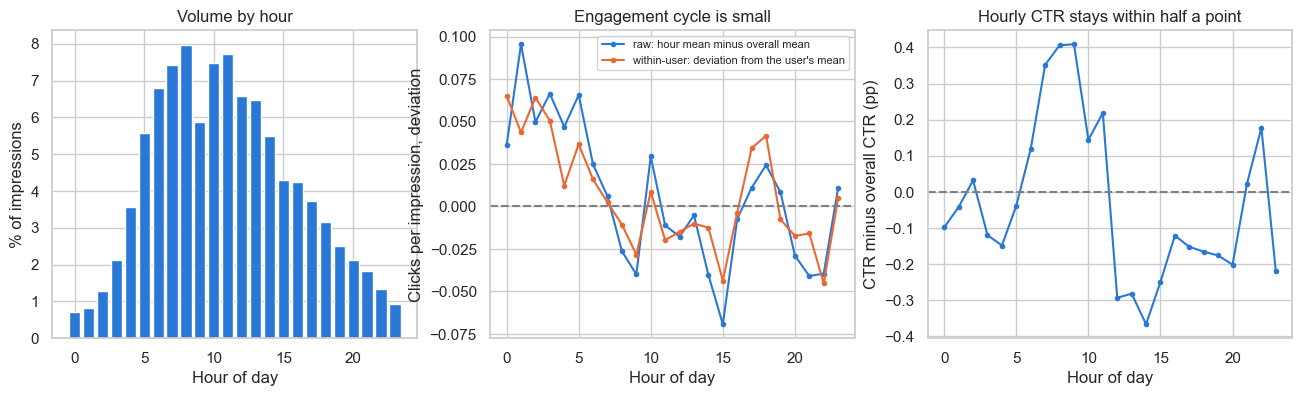

In [15]:
# Plot 2 of 3
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(by_hour.index, by_hour.impression_pct)
ax[0].set(xlabel="Hour of day", ylabel="% of impressions", title="Volume by hour")
ax[1].plot(
    by_hour.index,
    by_hour.raw_dev,
    marker="o",
    ms=3,
    label="raw: hour mean minus overall mean",
)
ax[1].plot(
    by_hour.index,
    by_hour.within_user,
    marker="o",
    ms=3,
    label="within-user: deviation from the user's mean",
)
ax[1].axhline(0, color="grey", ls="--")
ax[1].set(
    xlabel="Hour of day",
    ylabel="Clicks per impression, deviation",
    title="Engagement cycle is small",
)
ax[1].legend(fontsize=8)
ax[2].plot(by_hour.index, by_hour.ctr_dev_pp, marker="o", ms=3)
ax[2].axhline(0, color="grey", ls="--")
ax[2].set(
    xlabel="Hour of day",
    ylabel="CTR minus overall CTR (pp)",
    title="Hourly CTR stays within half a point",
)
plt.savefig(FIG_DIR / "art_06_hour_of_day.png", dpi=150, bbox_inches="tight")
plt.show()

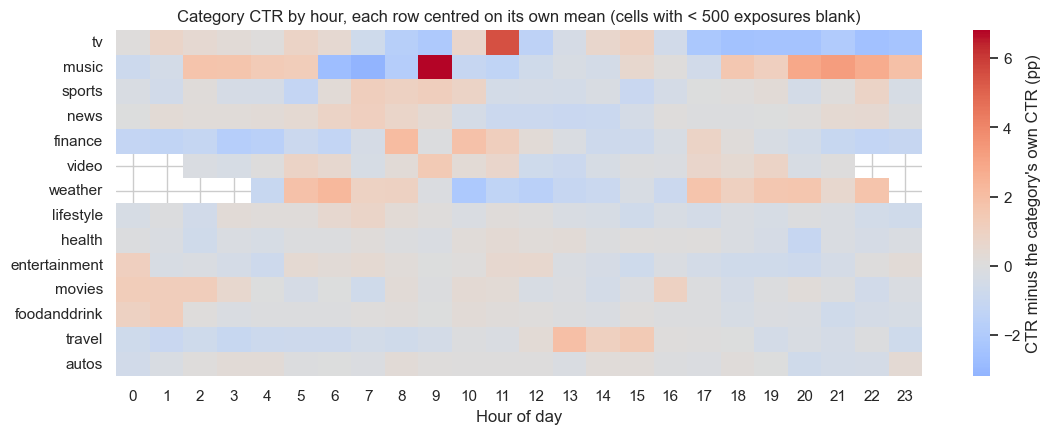

In [16]:
# Plot 3 of 3
plt.figure(figsize=(13, 4.5))
sns.heatmap(
    heat,
    cmap="coolwarm",
    center=0,
    cbar_kws={"label": "CTR minus the category's own CTR (pp)"},
)
plt.title(
    "Category CTR by hour, each row centred on its own mean (cells with < 500 exposures blank)"
)
plt.xlabel("Hour of day")
plt.ylabel("")
plt.savefig(FIG_DIR / "art_06_category_hour_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# 7. Time since the user's previous impression

* 58% of impressions have a previous visit in the window; the median gap is about 7 hours and 75% of gaps are under a day.
* Clicks per visit peak after a 6 to 24 hour gap and are lowest for immediate continuations and for returns after more than 3 days; within
  users the spread shrinks to about ±0.04 clicks, so much of the raw pattern is user composition.
* The gap is unrelated to hour of day (Spearman −0.01) and weakly related to history length (−0.19).

**Model Implications**
* `hours_since_previous_impression` plus a first-visit indicator is a small session feature; like hour of day it mostly informs calibration.

In [17]:
# 1. Gap since the user's previous impression
GAPS = ["<1 hour", "1-6 hours", "6-24 hours", "1-3 days", ">3 days"]
g = imp.sort_values(["user_code", "timestamp"]).copy()
g["gap_h"] = g.groupby("user_code").timestamp.diff().dt.total_seconds() / 3600
print(f"First impressions (no gap): {100 * g.gap_h.isna().mean():.1f}%")
g = g.dropna(subset=["gap_h"])
g["gap"] = pd.cut(g.gap_h, [-1, 1, 6, 24, 72, 1e9], labels=GAPS)
print(
    "Gap in hours:",
    g.gap_h.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1).to_dict(),
)
print(f"Spearman(gap, hour of day) = {stats.spearmanr(g.gap_h, g.hour).statistic:.2f}")
print(
    f"Spearman(gap, history length) = {stats.spearmanr(g.gap_h, g.history_len).statistic:.2f}"
)

# 2. Clicks per impression by gap, raw and within-user demeaned
gm = g[g.groupby("user_code").impression_uid.transform("size") > 1].copy()
gm["dev"] = gm.n_clicks - gm.groupby("user_code").n_clicks.transform("mean")
tbl = (
    g.groupby("gap", observed=True)
    .agg(
        impressions=("n_clicks", "size"),
        clicks_per_impression=("n_clicks", "mean"),
        mean_slate_len=("slate_len", "mean"),
    )
    .reindex(GAPS)
)
tbl["within_user"] = gm.groupby("gap", observed=True).dev.mean()
tbl["raw_dev"] = tbl.clicks_per_impression - g.n_clicks.mean()
print("\nClicks per impression by time since the previous impression:")
print(tbl.round(3))

First impressions (no gap): 42.2%
Gap in hours: {'count': 54923.0, 'mean': 14.0, 'std': 15.7, 'min': 0.0, '25%': 1.7, '50%': 7.4, '75%': 22.8, '90%': 33.6, 'max': 92.4}
Spearman(gap, hour of day) = -0.01
Spearman(gap, history length) = -0.19

Clicks per impression by time since the previous impression:
            impressions  clicks_per_impression  mean_slate_len  within_user  raw_dev
gap                                                                                 
<1 hour            9854                  1.438          33.258       -0.021   -0.070
1-6 hours         15761                  1.513          36.453       -0.038    0.005
6-24 hours        17782                  1.548          35.314        0.031    0.039
1-3 days          11041                  1.504          34.770        0.031   -0.004
>3 days             485                  1.414          35.495        0.002   -0.094


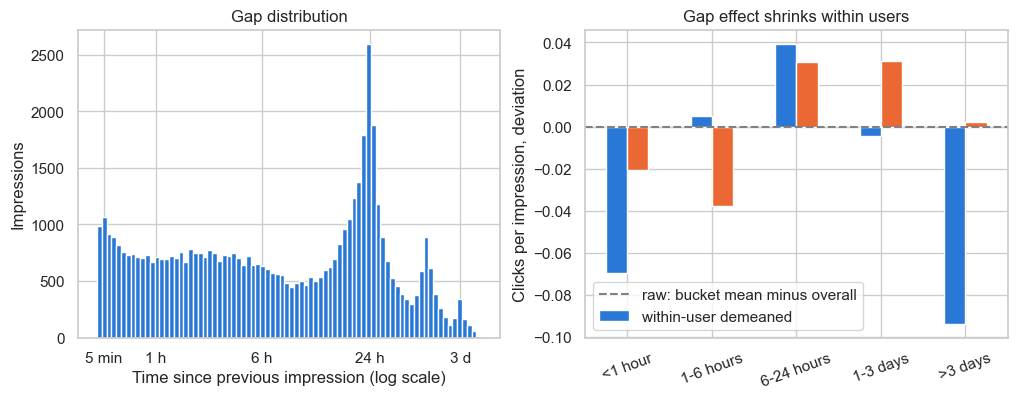

In [18]:
# Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(np.log1p(g.gap_h), bins=80)
ticks = [1 / 12, 1, 6, 24, 72]
ax[0].set_xticks(np.log1p(ticks))
ax[0].set_xticklabels(["5 min", "1 h", "6 h", "24 h", "3 d"])
ax[0].set(
    xlabel="Time since previous impression (log scale)",
    ylabel="Impressions",
    title="Gap distribution",
)
tbl[["raw_dev", "within_user"]].plot(kind="bar", ax=ax[1], rot=20)
ax[1].axhline(0, color="grey", ls="--")
ax[1].legend(["raw: bucket mean minus overall", "within-user demeaned"])
ax[1].set(
    xlabel="",
    ylabel="Clicks per impression, deviation",
    title="Gap effect shrinks within users",
)
plt.savefig(FIG_DIR / "art_07_recency_gap.png", dpi=150, bbox_inches="tight")
plt.show()

# Summary

| Finding | Decision |
|---|---|
| Short text, 5% missing abstracts, 12% no entities; subcategory long tail | title-first encoder, abstract mask, entity path optional, embed subcategory |
| 4% of shown articles take 80% of clicks; raw CTR unstable below 100 exposures | prior exposures / clicks / smoothed CTR, never whole-window CTR |
| Category CTR spread survives exposure control | `category` feature, compact encoding, cold-start fallback |
| CTR decays with article age; prior clicks predict CTR strongly | `article_age_hours` + censoring flag; hourly time-causal popularity, modelled jointly with age |
| 77% of test-day exposures (85% of clicks) are on articles unseen in train | content-based candidate generation; popularity must update through the test day |
| Time of day moves volume, not engagement | coarse day-part context feature, calibration not ranking |
| Gap effect small and partly composition | recency feature with first-visit flag, low priority |